In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [10]:
import pandas as pd

df = pd.read_csv('/content/sample_data/titanic.csv')

print("First five rows:")
display(df.head())

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

First five rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Dataset shape: (891, 12)

Column names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [11]:
# Display dataset information
print("DATASET INFORMATION")
df.info()

# Count missing values in each column
print("\nMISSING VALUES")
print(df.isnull().sum())

# Display statistical summary
print("\nSTATISTICAL SUMMARY")
display(df.describe())

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

MISSING VALUES
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


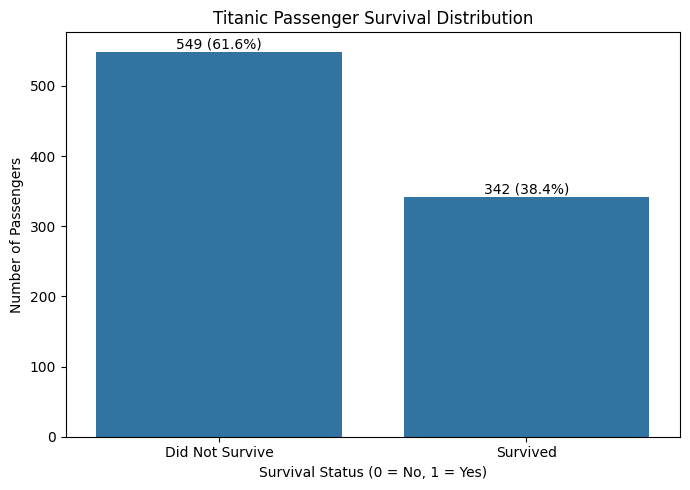


Survival summary:
Did not survive: 549 passengers
Survived: 342 passengers


In [12]:
# Analyze passenger survival
survival_counts = df["Survived"].value_counts().sort_index()
survival_percentages = df["Survived"].value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=survival_counts.index,
    y=survival_counts.values
)

plt.title("Titanic Passenger Survival Distribution")
plt.xlabel("Survival Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.xticks([0, 1], ["Did Not Survive", "Survived"])

for i, count in enumerate(survival_counts.values):
    plt.text(
        i,
        count + 5,
        f"{count} ({survival_percentages.iloc[i]:.1f}%)",
        ha="center"
    )

plt.tight_layout()
plt.show()

print("\nSurvival summary:")
print(f"Did not survive: {survival_counts.loc[0]} passengers")
print(f"Survived: {survival_counts.loc[1]} passengers")

Survival percentage within each gender:


Survived,0,1
Sex,,
female,25.80,74.20
male,81.11,18.89


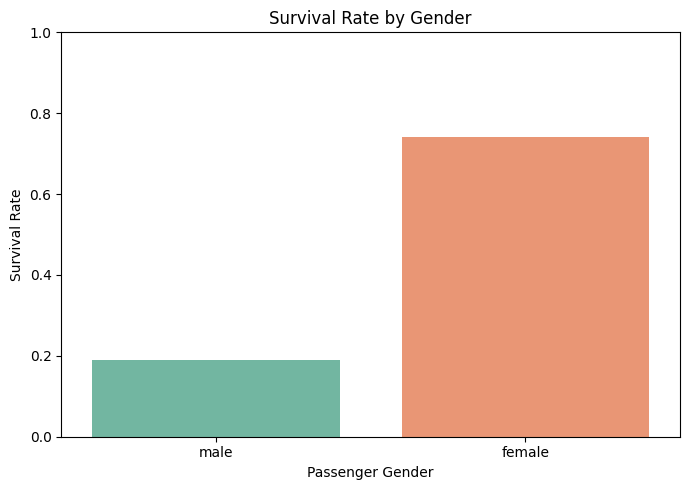

In [13]:
# Compare survival outcomes across passenger groups
gender_table = pd.crosstab(
    df["Sex"],
    df["Survived"],
    normalize="index"
) * 100

print("Survival percentage within each gender:")
display(gender_table.round(2))

plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Sex",
    y="Survived",
    hue="Sex",
    estimator="mean",
    errorbar=None,
    palette="Set2",
    legend=False
)

plt.title("Survival Rate by Gender")
plt.xlabel("Passenger Gender")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

Interpretation: The analysis shows that 74.20% of female passengers survived, compared with 18.89% of male passengers. Female passengers therefore had a substantially higher survival rate in this dataset. This suggests that gender was strongly associated with survival outcomes and may be an important predictor for the Logistic Regression model. However, this relationship alone does not establish causation.

Survival statistics by passenger class:


,Passenger Count,Survival Rate,Survival Rate (%)
Pclass,,,
1,216,0.63,62.96
2,184,0.47,47.28
3,491,0.24,24.24


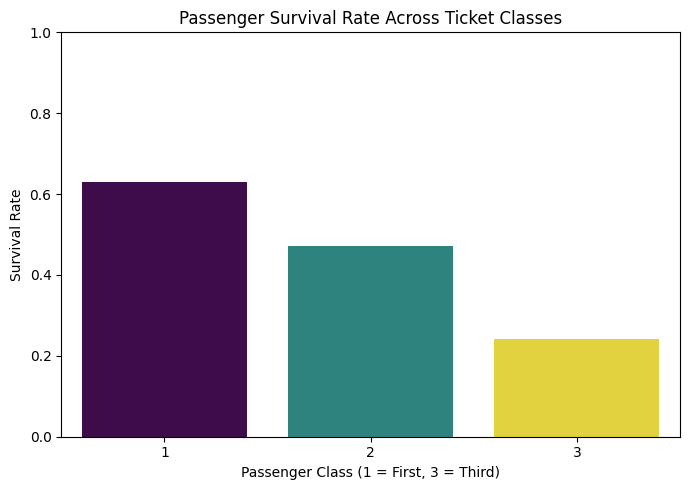

In [14]:
# Calculate survival rates for each passenger class
class_survival = df.groupby("Pclass")["Survived"].agg(
    ["count", "mean"]
)

class_survival.columns = ["Passenger Count", "Survival Rate"]
class_survival["Survival Rate (%)"] = (
    class_survival["Survival Rate"] * 100
)

print("Survival statistics by passenger class:")
display(class_survival.round(2))

# Visualize the survival rates
plt.figure(figsize=(7, 5))

sns.barplot(
    data=df,
    x="Pclass",
    y="Survived",
    hue="Pclass",
    estimator="mean",
    errorbar=None,
    palette="viridis",
    legend=False
)

plt.title("Passenger Survival Rate Across Ticket Classes")
plt.xlabel("Passenger Class (1 = First, 3 = Third)")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

Interpretation: The analysis shows that passengers travelling in first class had the highest survival rate at 62.96%, followed by second-class passengers at 47.28%. Third-class passengers had the lowest survival rate at 24.24%, despite representing the largest group in the dataset. This pattern suggests that passenger class was associated with survival outcomes and may provide useful information for the prediction model. However, these results describe an association and do not establish that passenger class alone caused the differences in survival.

Age summary statistics:


,Age
count,714.00
mean,29.70
std,14.53
min,0.42
25%,20.12
50%,28.00
75%,38.00
max,80.00



Missing age values: 177


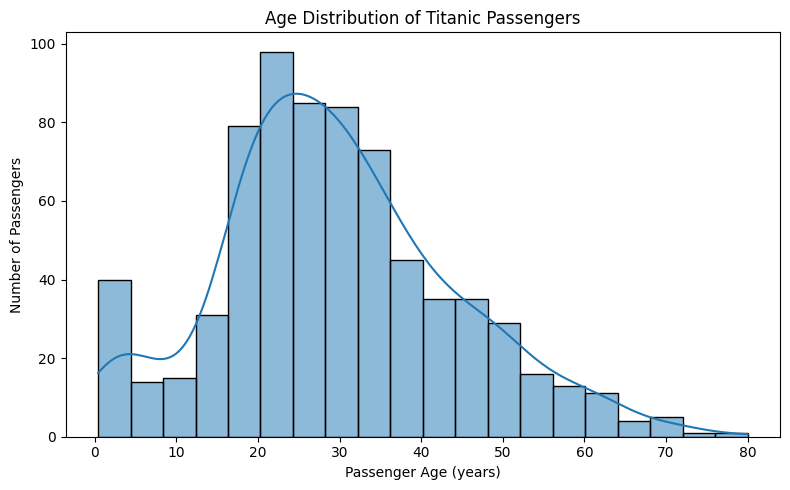

In [15]:
# Summarize passenger ages
print("Age summary statistics:")
display(df["Age"].describe().round(2))

print("\nMissing age values:", df["Age"].isna().sum())

# Visualize the age distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=20,
    kde=True
)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Passenger Age (years)")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

**Interpretation:** The age analysis shows that the 714 passengers with recorded ages had a mean age of 29.70 years and a median age of 28 years. Ages ranged from 0.42 to 80 years, indicating that passengers belonged to a wide range of age groups. The mean is slightly higher than the median, suggesting some right-skewness in the age distribution. Additionally, 177 records have missing age values, which must be handled during preprocessing before training the Logistic Regression model.


Ticket fare summary:


,Fare
count,891.00
mean,32.20
std,49.69
min,0.00
25%,7.91
50%,14.45
75%,31.00
max,512.33


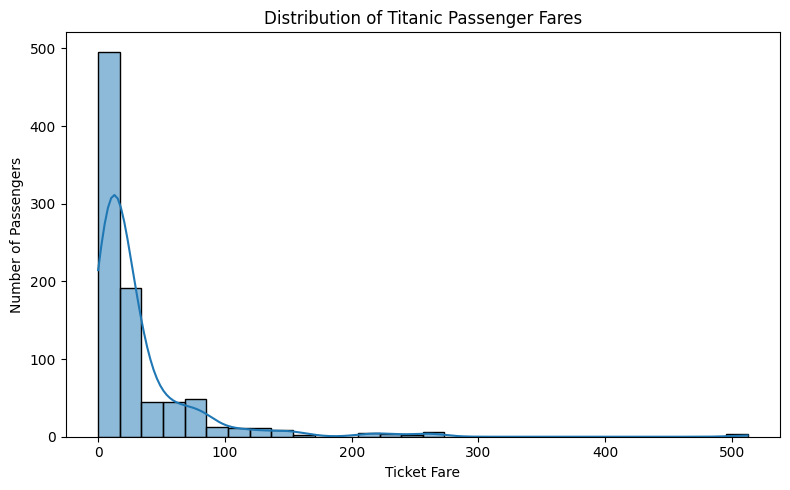


Highest ticket fares:


,Pclass,Fare,Survived
258,1,512.3292,1
679,1,512.3292,1
737,1,512.3292,1
27,1,263.0000,0
88,1,263.0000,1


In [16]:
# Examine ticket fare statistics
print("Ticket fare summary:")
display(df["Fare"].describe().round(2))

# Plot the fare distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Fare",
    bins=30,
    kde=True
)

plt.title("Distribution of Titanic Passenger Fares")
plt.xlabel("Ticket Fare")
plt.ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

# Identify potential extreme fare values
print("\nHighest ticket fares:")
display(df.nlargest(5, "Fare")[["Pclass", "Fare", "Survived"]])

**Interpretation:** The ticket fare analysis shows a mean fare of 32.20 and a median of 14.45. The maximum fare of 512.33 is substantially higher than the median, indicating a right-skewed distribution with some unusually high fares. The highest fares in the displayed records belong to first-class passengers. Fare may therefore provide useful information for predicting survival, although its relationship with survival must be evaluated using the model.


Correlation with survival:


,Correlation with Survived
Survived,1.000
Fare,0.257
Parch,0.082
PassengerId,-0.005
SibSp,-0.035
Age,-0.077
Pclass,-0.338


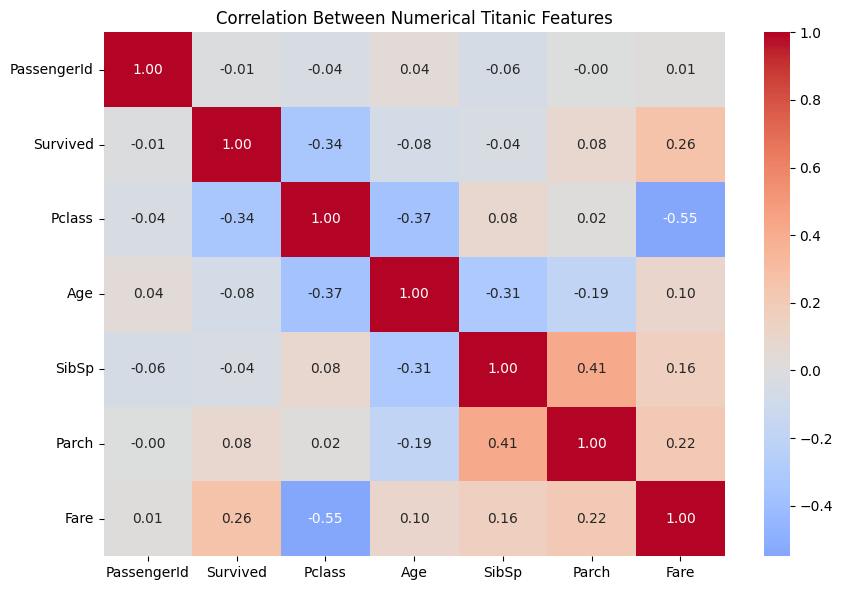

In [17]:
# Calculate correlations between numerical variables
numeric_df = df.select_dtypes(include="number")

correlation_matrix = numeric_df.corr()

print("Correlation with survival:")
display(
    correlation_matrix["Survived"]
    .sort_values(ascending=False)
    .to_frame("Correlation with Survived")
    .round(3)
)

# Visualize correlations
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Between Numerical Titanic Features")
plt.tight_layout()
plt.show()

**Interpretation:** The correlation analysis indicates that passenger class has the strongest negative correlation with survival among the numerical variables, with a coefficient of −0.338. Fare shows a positive correlation of 0.257. Age, SibSp, and Parch have comparatively weak linear correlations with survival. PassengerId has almost no correlation and is an identifier rather than a meaningful predictive feature. These findings help guide feature selection, but correlation alone cannot establish causation or determine the complete predictive importance of a variable.


In [18]:
# Explore categorical features
print("Passenger counts by gender:")
display(df["Sex"].value_counts())

print("\nPassengers by embarkation port:")
display(df["Embarked"].value_counts(dropna=False))

print("\nSurvival counts by gender:")
display(pd.crosstab(df["Sex"], df["Survived"]))

print("\nSurvival counts by embarkation port:")
display(pd.crosstab(df["Embarked"], df["Survived"], dropna=False))

Passenger counts by gender:


,count
Sex,
male,577
female,314



Passengers by embarkation port:


,count
Embarked,
S,644
C,168
Q,77
NaN,2



Survival counts by gender:


Survived,0,1
Sex,,
female,81,233
male,468,109



Survival counts by embarkation port:


Survived,0,1
Embarked,,
C,75,93
Q,47,30
S,427,217
NaN,0,2


**Interpretation:** The categorical analysis shows that male passengers formed the larger group, with 577 records, compared with 314 female passengers. Survival outcomes differed by gender: 233 female passengers survived, while 468 male passengers did not survive. Southampton was the most common embarkation port, accounting for 644 passengers. Since the number of passengers differs across ports, survival rates should be compared rather than relying only on raw counts. Two records have missing embarkation information and will be handled during preprocessing.


Data preprocessing

In [19]:
# Create a modelling dataset
model_df = df[
    ["Survived", "Pclass", "Sex", "Age", "SibSp",
     "Parch", "Fare", "Embarked"]
].copy()

# Handle missing numerical values using the median
model_df["Age"] = model_df["Age"].fillna(
    model_df["Age"].median()
)

# Handle missing categorical values using the most frequent category
model_df["Embarked"] = model_df["Embarked"].fillna(
    model_df["Embarked"].mode()[0]
)

# Encode categorical variables using one-hot encoding
model_df = pd.get_dummies(
    model_df,
    columns=["Sex", "Embarked"],
    drop_first=True,
    dtype=int
)

print("Missing values after preprocessing:")
print(model_df.isnull().sum())

print("\nProcessed dataset shape:", model_df.shape)

print("\nProcessed columns:")
print(model_df.columns.tolist())

display(model_df.head())

Missing values after preprocessing:
Survived      0
Pclass        0
Age           0
SibSp         0
Parch         0
Fare          0
Sex_male      0
Embarked_Q    0
Embarked_S    0
dtype: int64

Processed dataset shape: (891, 9)

Processed columns:
['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S']


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,1,0,1
1,1,1,38.0,1,0,71.2833,0,0,0
2,1,3,26.0,0,0,7.9250,0,0,1
3,1,1,35.0,1,0,53.1000,0,0,1
4,0,3,35.0,0,0,8.0500,1,0,1


In [21]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = model_df.drop(columns=["Survived"])
y = model_df["Survived"]

# Split data: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features shape: (712, 8)
Testing features shape: (179, 8)

Training target distribution:
Survived
0    439
1    273
Name: count, dtype: int64

Testing target distribution:
Survived
0    110
1     69
Name: count, dtype: int64


In [22]:
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
model = LogisticRegression(max_iter=1000)

# Train the model using the training data
model.fit(X_train, y_train)

# Predict survival outcomes for the test data
y_pred = model.predict(X_test)

# Estimate survival probabilities
y_prob = model.predict_proba(X_test)[:, 1]

print("Logistic Regression model trained successfully!")
print("Number of test predictions:", len(y_pred))
print("\nFirst 10 actual outcomes:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted outcomes:")
print(y_pred[:10])

Logistic Regression model trained successfully!
Number of test predictions: 179

First 10 actual outcomes:
[0, 0, 1, 0, 1, 1, 1, 0, 0, 0]

First 10 predicted outcomes:
[0 0 0 0 1 0 1 0 0 0]


In [23]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("LOGISTIC REGRESSION - MODEL EVALUATION")
print("-" * 40)
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=[
    "Did Not Survive",
    "Survived"
]))

LOGISTIC REGRESSION - MODEL EVALUATION
----------------------------------------
Accuracy:  0.8045
Precision: 0.7931
Recall:    0.6667
F1-score:  0.7244
ROC-AUC:   0.8443

Confusion Matrix:
[[98 12]
 [23 46]]

Classification Report:
                 precision    recall  f1-score   support

Did Not Survive       0.81      0.89      0.85       110
       Survived       0.79      0.67      0.72        69

       accuracy                           0.80       179
      macro avg       0.80      0.78      0.79       179
   weighted avg       0.80      0.80      0.80       179



**Interpretation:** The Logistic Regression model achieved an accuracy of 80.45% on the 179 test records, correctly classifying 144 passengers. Its precision of 79.31% indicates that most passengers predicted to survive actually survived. The recall of 66.67% shows that the model identified approximately two-thirds of the actual survivors. The F1-score of 72.44% represents the balance between precision and recall, while the ROC-AUC of 84.43% indicates good discrimination between survivors and non-survivors. The confusion matrix shows 98 correctly identified non-survivors and 46 correctly identified survivors. However, 23 actual survivors were classified as non-survivors, so the model does not identify every survivor.


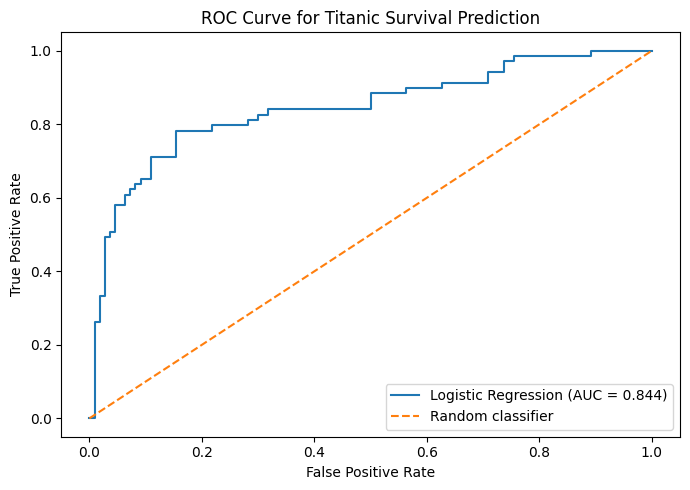

In [24]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

# Plot the ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.title("ROC Curve for Titanic Survival Prediction")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation:** The ROC curve evaluates the ability of the Logistic Regression model to distinguish between passengers who survived and those who did not survive. The model achieved a ROC-AUC score of **0.8443 (84.43%)**, indicating good classification performance. The curve shows how the true positive rate changes with the false positive rate at different classification thresholds.


In [25]:
coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_[0]
})

coefficients = coefficients.sort_values(
    by="Coefficient", ascending=False
)

display(coefficients)

,Feature,Coefficient
6,Embarked_Q,0.278320
4,Fare,0.002255
1,Age,-0.038464
3,Parch,-0.071496
2,SibSp,-0.243809
7,Embarked_S,-0.381616
0,Pclass,-1.090476
5,Sex_male,-2.555755


**Interpretation:**

The coefficient analysis shows how different passenger features are associated with the likelihood of survival.

1. **Sex_male (-2.556):** This has the largest negative coefficient, indicating that male passengers had lower predicted survival odds than female passengers, when other features are held constant.
2. **Pclass (-1.090):** The negative coefficient indicates that passengers in higher-numbered classes, such as third class, had lower predicted survival odds.
3. **Embarked_S (-0.382):** Passengers who embarked at Southampton had lower predicted survival odds compared with the reference embarkation category, Cherbourg, holding other features constant.
4. **SibSp (-0.244):** A negative coefficient indicates an association between having more siblings or spouses aboard and lower predicted survival odds.
5. **Parch (-0.071):** This has a small negative coefficient, suggesting a relatively weak negative association with predicted survival odds.
6. **Age (-0.038):** The negative coefficient indicates that increasing age was associated with slightly lower predicted survival odds.
7. **Fare (+0.002):** The small positive coefficient indicates a slight positive association between fare and predicted survival odds.
8. **Embarked_Q (+0.278):** This positive coefficient indicates higher predicted survival odds compared with the reference embarkation category, Cherbourg, holding other features constant.

**Conclusion:** Sex and passenger class have the largest coefficient magnitudes in this model. However, coefficients alone do not establish statistical significance or causation.


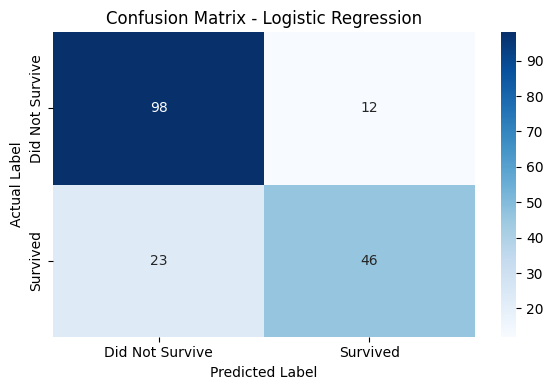

In [26]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Did Not Survive", "Survived"],
    yticklabels=["Did Not Survive", "Survived"]
)

plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

**Interpretation:**

The confusion matrix evaluates the Logistic Regression model's predictions on the test dataset.

* **True Negatives (98):** The model correctly predicted that 98 passengers did not survive.
* **True Positives (46):** The model correctly predicted that 46 passengers survived.
* **False Positives (12):** The model predicted that 12 passengers survived, but they did not.
* **False Negatives (23):** The model predicted that 23 passengers did not survive, but they survived.

Overall, the model correctly classified 144 out of 179 passengers, achieving an accuracy of approximately 80.45%. The model identified more passengers who did not survive than passengers who survived, so improving its ability to identify survivors could be a useful direction for further improvement.
